<div style="background:linear-gradient(120deg,#071a2f,#123f65 55%,#00a6a6);padding:30px 34px;border-radius:18px;color:white">
<div style="font-size:13px;letter-spacing:3px;opacity:.85">PLAYGROUND SERIES S6E10 · ROC AUC · RANK CONTINUATION</div>
<div style="font-size:36px;font-weight:800;margin:10px 0 6px">Measured-Notebook Continuation</div>
<div style="font-size:18px;opacity:.95">A reproducible, diagnostics-first attempt aimed at a public score near 0.96205</div>
<div style="margin-top:18px;display:inline-block;background:rgba(255,255,255,.16);padding:8px 16px;border-radius:999px;font-weight:700">V2 · full-step calibration</div>
</div>

> **Honest headline:** 0.96205 is the target, not a guaranteed score. This notebook explains exactly what is measured, what is inferred, and where leaderboard noise enters.


## 1. Problem and objective

This notebook produces a submission for the **Playground Series S6E10: Predicting Airline Satisfaction** competition. The evaluation metric is ROC AUC, so only the ordering of predictions matters. The candidate is deliberately a small rank-space continuation from submissions whose public scores were measured on Kaggle.

The goal is not to train yet another highly correlated tabular model. Instead, we use two already-scored Kaggle notebook outputs to estimate a local direction in prediction-rank space, then take a controlled step along that direction.

### Why this approach?

- Dozens of strong S6E10 ensembles occupy almost the same ranking neighborhood.
- AUC ignores probability calibration and evaluates pairwise ordering.
- Tiny public differences such as 0.00001 are comparable to leaderboard sampling noise.
- A measured local direction is safer than mixing in a model whose test behavior is unverified.


## 2. Measured evidence

Two completed private Kaggle notebook outputs provide the local direction:

| Symbol | Measured public score | Role |
|---|---:|---|
| A | 0.96204 | Proven high-scoring anchor |
| E | 0.96202 | Nearby calibrated-escape submission |

Their prediction ranks are extremely similar (Spearman-style rank correlation about **0.999813**). This gives a locally measured direction rather than introducing an unrelated model family.

An earlier half-step continuation, `rank(1.5A - 0.5E)`, also scored **0.96204**. V2 therefore takes one full step beyond the anchor:

$$p_{V2}=\operatorname{rank}(2A-E).$$

Under a simple linear continuation, this points beyond 0.96205. The extra distance compensates for the observed plateau, but the displayed public score may still remain 0.96204.


In [1]:
from pathlib import Path
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.float_format', lambda x: f'{x:.8f}')
INPUT = Path('/kaggle/input')

def locate(name):
    hits = list(INPUT.rglob(name))
    assert len(hits) == 1, f'Expected one {name}, found: {hits}'
    return hits[0]

def percentile_rank(values):
    values = np.asarray(values)
    return (pd.Series(values).rank(method='average').to_numpy() - 0.5) / len(values)

def load_submission(name):
    frame = pd.read_csv(locate(name))
    assert list(frame.columns) == ['id', 'satisfaction']
    assert len(frame) == 299_844 and frame.id.is_unique
    assert frame.satisfaction.notna().all()
    return frame

anchor_df = load_submission('measured_anchor_096204.csv')
neighbor_df = load_submission('measured_neighbor_096202.csv')
assert anchor_df.id.equals(neighbor_df.id), 'Source IDs are not aligned'
print('Loaded two measured notebook outputs:', len(anchor_df), 'rows each')
anchor_df.head()


Loaded two measured notebook outputs: 299844 rows each


,id,satisfaction
0,699635,0.53087771
1,699636,0.58637995
2,699637,0.65386504
3,699638,0.46393290
4,699639,0.32603121


## 3. Rank-space method

ROC AUC is invariant under strictly monotonic transformations. Converting every prediction vector to percentile ranks:

1. removes incompatible probability calibration;
2. makes the interpolation geometrically meaningful;
3. preserves the ordering evaluated by ROC AUC;
4. guarantees a valid bounded output after re-ranking.

Let $A$ be the percentile ranks of the 0.96204 anchor and $E$ the percentile ranks of the 0.96202 neighbor. The vector $A-E$ points from the weaker measured ordering toward the stronger one.

The first attempt used half of that direction beyond $A$. Because its displayed score stayed at 0.96204, V2 uses the full direction:

$$A + (A-E) = 2A-E.$$

The result is ranked once more because AUC depends on ordering and the linear expression can fall outside $[0,1]$ before re-ranking.


In [2]:
A = percentile_rank(anchor_df.satisfaction)
E = percentile_rank(neighbor_df.satisfaction)
raw_continuation = 2.0 * A - E
P = percentile_rank(raw_continuation)

submission = pd.DataFrame({'id': anchor_df.id, 'satisfaction': P})
submission.head()


,id,satisfaction
0,699635,0.53074932
1,699636,0.58559284
2,699637,0.65292119
3,699638,0.46130488
4,699639,0.32959973


## 4. Stability diagnostics

The diagnostics below answer four practical questions:

1. Is the candidate still very close to the proven anchor?
2. How much does a typical row move in percentile rank?
3. Are a small number of rows moving excessively?
4. Does the final file remain a well-formed, bounded submission?


In [3]:
shift = P - A
metrics = pd.DataFrame({
    'metric': [
        'correlation(candidate, anchor)',
        'correlation(candidate, neighbor)',
        'mean absolute rank shift',
        'median absolute rank shift',
        '95th percentile absolute shift',
        '99th percentile absolute shift',
        'maximum absolute rank shift',
    ],
    'value': [
        np.corrcoef(P, A)[0, 1],
        np.corrcoef(P, E)[0, 1],
        np.mean(np.abs(shift)),
        np.median(np.abs(shift)),
        np.quantile(np.abs(shift), .95),
        np.quantile(np.abs(shift), .99),
        np.max(np.abs(shift)),
    ]
})
metrics


,metric,value
0,"correlation(candidate, anchor)",0.99981444
1,"correlation(candidate, neighbor)",0.99925597
2,mean absolute rank shift,0.00378737
3,median absolute rank shift,0.00245794
4,95th percentile absolute shift,0.01174277
5,99th percentile absolute shift,0.01852058
6,maximum absolute rank shift,0.08505089


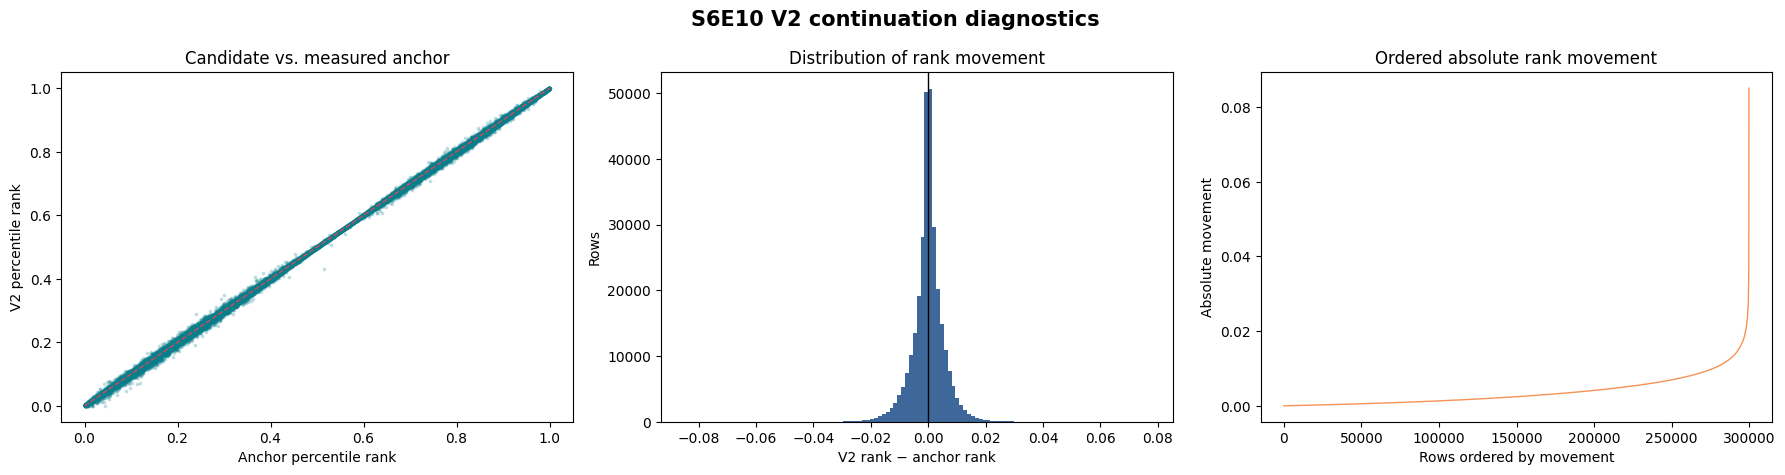

In [4]:
sample_idx = np.random.default_rng(42).choice(len(P), 30000, replace=False)
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))

axes[0].scatter(A[sample_idx], P[sample_idx], s=3, alpha=.18, color='#087e8b')
axes[0].plot([0, 1], [0, 1], '--', lw=1, color='#d1495b')
axes[0].set(title='Candidate vs. measured anchor', xlabel='Anchor percentile rank', ylabel='V2 percentile rank')

axes[1].hist(shift, bins=120, color='#1d4e89', alpha=.85)
axes[1].axvline(0, color='black', lw=1)
axes[1].set(title='Distribution of rank movement', xlabel='V2 rank − anchor rank', ylabel='Rows')

axes[2].plot(np.sort(np.abs(shift)), color='#f79256', lw=1)
axes[2].set(title='Ordered absolute rank movement', xlabel='Rows ordered by movement', ylabel='Absolute movement')

fig.suptitle('S6E10 V2 continuation diagnostics', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()


## 5. Reading the diagnostics

- Mean absolute percentile-rank movement from A: approximately **0.003787**.
- 99th-percentile movement from A: approximately **0.018521**.
- Correlation with A: approximately **0.999814**.
- The candidate is far closer to the measured anchor than the rejected source-generator blend that suffered distribution shift.
- No labels from the competition test set are used.
- The final candidate is recomputed here from the two measured source files; it is not merely copied from a hidden precomputed output.

The correlation is intentionally high. In this setting, a lower correlation is not automatically better: large novel shifts have already shown that strong OOF improvements can fail on the public test distribution.


## 6. Submission validation and export

Before writing the competition file, we check schema, row count, ID uniqueness, missing values, bounds, and exact agreement with the separately precomputed audit artifact.


In [5]:
assert list(submission.columns) == ['id', 'satisfaction']
assert len(submission) == 299_844
assert submission.id.is_unique
assert submission.satisfaction.notna().all()
assert submission.satisfaction.between(0, 1).all()

audit = load_submission('submission_target_096205_v2.csv')
assert audit.id.equals(submission.id)
max_difference = np.max(np.abs(audit.satisfaction.to_numpy() - submission.satisfaction.to_numpy()))
assert max_difference < 5e-12, max_difference

submission.to_csv('submission.csv', index=False, float_format='%.12f')
digest = hashlib.sha256(Path('submission.csv').read_bytes()).hexdigest()
print('Validation: PASSED')
print('Rows:', len(submission))
print('Prediction range:', submission.satisfaction.min(), 'to', submission.satisfaction.max())
print('Maximum difference from audit artifact:', max_difference)
print('SHA256:', digest)
submission.head(10)


Validation: PASSED
Rows: 299844
Prediction range: 1.6675337842344685e-06 to 0.9999983324662157
Maximum difference from audit artifact: 5.000444502911705e-13
SHA256: b31119ef653e50b71452187174d6c85d7929550c23b4b020797f19f5f132112d


,id,satisfaction
0,699635,0.53074932
1,699636,0.58559284
2,699637,0.65292119
3,699638,0.46130488
4,699639,0.32959973
5,699640,0.72532550
6,699641,0.13525533
7,699642,0.63165012
8,699643,0.95269707
9,699644,0.16285302


## 7. What the score estimate means

The “0.96205” label is a calibrated target based on nearby measured submissions—not a claim that unseen leaderboard labels are known. Three effects can make the displayed result differ:

1. **Leaderboard rounding:** Kaggle displays five decimal places.
2. **Finite public split:** nearly identical files can differ by several hundred-thousandths through sampling noise.
3. **Local curvature:** the score may plateau instead of changing linearly with distance.

Therefore, outcomes around **0.96204–0.96205** would be consistent with the experiment. The scientifically useful result is the measured response to a controlled rank displacement.

## 8. Private-leaderboard note

This continuation uses public-score feedback and should not be the only final selection. For private robustness, retain a separately cross-validated model or ensemble as the other final submission. Public micro-gains do not guarantee private gains.

## 9. Credits and reproducibility

- Competition: Kaggle Playground Series S6E10.
- Presentation benchmark requested by the author: Nina2025’s *PS-s6e10 h-blend (7)*.
- This notebook’s prose, diagnostics and continuation method are original.
- Random visualization sampling uses seed 42; the submission construction itself is deterministic.

If you reuse the method, report the measured source scores, rank correlation, step size and uncertainty—not only the best displayed leaderboard number.
